# Multi-view simulations 
We use the paper's linear-kernel, row-wise information-plus-noise model
\[
E_s=V_s+\frac{1}{\sqrt{m_s}}\Xi_s,\qquad
K_s^{\rm obs}=\frac1N E_sE_s^\top,
\qquad \widehat Z=\operatorname{TopEig}_d\!\left(\sum_s w_sK_s^{\rm obs}\right).
\]
Each row of \(\Xi_s\) is an independently drawn Gaussian vector. **Experiment 1 and 2 retain the paper's** \(N=60,d=4,S=4\) **and original signal spectra**. Only **Experiment 3** changes its latent rank to \(d_{\rm sup}=16\) (and extends the signal spectra accordingly) to make imperfect representation recovery visible in the \(m\)-sweep.

**No ground-truth information enters Experiment 2's deployable weighting rule.** Its \(\widehat\gamma_s\), \(\widehat B_s\), \(\widehat\nu_s\), and \(\widehat\sigma_{\infty,s}\) are calculated from **only** the observed \(E_s\). Simulation-only ground truth \((Z_\star,V_s,\Sigma_s)\) is accessed *exclusively* to generate data and to evaluate the labeled **oracle benchmark** and recovery errors, never to choose the inverse-variance weights.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress
from IPython.display import display
import os
import warnings

warnings.filterwarnings("ignore")

FIGDIR = "figs_entity_kernel"
os.makedirs(FIGDIR, exist_ok=True)

np.set_printoptions(precision=4, suppress=True)

# --------------------------
# Global parameters
# --------------------------
N, d, S = 60, 4, 4

SPECTRA = [
    np.array([10.0, 7.0, 4.5, 2.0]),
    np.array([7.0,  5.0, 3.0, 1.5]),
    np.array([4.8, 3.5, 2.0, 1.0]),
    np.array([8.5, 6.0, 3.5, 1.8]),
]

M_VALUES = [50, 100, 200, 400, 800]
M_HET = [800, 400, 200, 100]

SIGMA_ISO_COMMON = 0.25
SIGMA_VIEW = np.array([0.15, 0.20, 0.25, 0.30])
ANISO_SCALES = np.array([0.8, 1.2, 2.0, 2.8])
ANISO_RANKS = np.array([6, 6, 8, 8], dtype=int)

UNIFORM_W = np.ones(S) / S

N_REPS_RATE = 20
N_REPS_WEIGHT = 15

COL = {
    "isotropic": "#1f77b4",
    "anisotropic": "#d62728",
    "target": "#555555",
    "uniform": "#888888",
    "inverse_variance": "#2ca02c",
    "oracle": "#9467bd",
    "pretrained": "#1f77b4",
}


In [2]:
# --------------------------
# Linear algebra utilities
# --------------------------
def make_z_star(N, d, seed=1):
    """Random orthonormal N x d entity subspace."""
    rng = np.random.default_rng(seed)
    Q, _ = np.linalg.qr(rng.standard_normal((N, d + 8)))
    return Q[:, :d]

def top_eigvecs(A, d):
    """Top-d eigenvectors of a symmetric matrix."""
    vals, vecs = np.linalg.eigh((A + A.T) / 2)
    idx = np.argsort(vals)[::-1][:d]
    return vecs[:, idx]

def eigengap(A, d):
    vals = np.linalg.eigvalsh((A + A.T) / 2)
    vals = np.sort(vals)[::-1]
    return vals[d-1] - vals[d]

def sin_theta_operator(U, V):
    """Operator norm of sin principal angles."""
    svals = np.linalg.svd(U.T @ V, compute_uv=False)
    svals = np.clip(svals, 0.0, 1.0)
    return np.sqrt(max(0.0, 1.0 - np.min(svals) ** 2))

def sin_theta_fro(U, V):
    """Frobenius norm of sin principal angles."""
    svals = np.linalg.svd(U.T @ V, compute_uv=False)
    svals = np.clip(svals, 0.0, 1.0)
    return np.sqrt(np.sum(1.0 - svals ** 2))



In [3]:
# --------------------------
# Linear-kernel factor-model DGP
# --------------------------
def make_loadings(m, eigvals, N, rng):
    """
    Construct B_s in R^{m x d} such that B_s^T B_s = N * diag(eigvals).
    Then V_s = Z_star B_s^T satisfies (1/N) V_s V_s^T = Z_star diag(eigvals) Z_star^T.
    """
    Q, _ = np.linalg.qr(rng.standard_normal((m, len(eigvals))))
    return np.sqrt(N) * Q @ np.diag(np.sqrt(eigvals))

def make_signal_codes(Z_star, eigvals, m, rng):
    """Return V_s in R^{N x m} and loadings B_s."""
    B = make_loadings(m, eigvals, Z_star.shape[0], rng)
    V = Z_star @ B.T
    return V, B

def make_fixed_anisotropic_cov(m, rank, scale, sigma_base, rng):
    """Create a fixed SPD covariance matrix for one row-noise vector in R^m."""
    rank_eff = min(int(rank), int(m))
    Q, _ = np.linalg.qr(rng.standard_normal((m, rank_eff)))
    eigs = np.linspace(1.5 * scale, 0.5 * scale, rank_eff)
    Sigma = (sigma_base ** 2) * np.eye(m) + Q @ np.diag(eigs) @ Q.T
    return 0.5 * (Sigma + Sigma.T)

def get_noise_covariance(regime, m, view_idx, seed=1234):
    if regime == "isotropic":
        return (SIGMA_ISO_COMMON ** 2) * np.eye(m)
    if regime == "anisotropic":
        rng = np.random.default_rng(seed + view_idx)
        return make_fixed_anisotropic_cov(
            m=m,
            rank=int(ANISO_RANKS[view_idx]),
            scale=float(ANISO_SCALES[view_idx]),
            sigma_base=float(SIGMA_VIEW[view_idx]),
            rng=rng,
        )
    raise ValueError("regime must be 'isotropic' or 'anisotropic'.")

def add_gaussian_noise(V, Sigma, rng):
    """
    Observed codes E = V + Xi C^T / sqrt(m), where rows of Xi are iid N(0, I).
    Hence the row-noise vectors are independent across entities, each with covariance Sigma / m.
    """
    N_, m = V.shape
    C = np.linalg.cholesky(0.5 * (Sigma + Sigma.T) + 1e-10 * np.eye(m))
    Xi = rng.standard_normal((N_, m))
    return V + (Xi @ C.T) / np.sqrt(m)

def linear_kernel(E):
    """Entity inner-product kernel with 1/N normalization."""
    return (E @ E.T) / E.shape[0]

def row_noise_shift(Sigma, m, N):
    """Expected diagonal kernel shift under row-wise independent Gaussian noise."""
    return np.trace(0.5 * (Sigma + Sigma.T)) / (m * N)

def make_view_matrices(Z_star, eigvals, m, Sigma, rng):
    """
    Construct pure signal codes, observed codes, and linear-kernel matrices for one view.
    Under row-wise independent Gaussian noise, E[K_obs] = K_sig + c_s I_N,
    where c_s = tr(Sigma) / (m N).
    """
    V, B = make_signal_codes(Z_star, eigvals, m, rng)
    E = add_gaussian_noise(V, Sigma, rng)
    K_sig = linear_kernel(V)
    K_obs = linear_kernel(E)
    K_tar = K_sig + row_noise_shift(Sigma, m, Z_star.shape[0]) * np.eye(Z_star.shape[0])
    return {
        "V": V,
        "E": E,
        "B": B,
        "Sigma": Sigma,
        "K_sig": K_sig,
        "K_obs": K_obs,
        "K_tar": K_tar,
        "m": m,
    }

def aggregate_kernel(view_dicts, key, weights):
    K = np.zeros_like(view_dicts[0][key])
    for w, view in zip(weights, view_dicts):
        K += w * view[key]
    return K


In [4]:
# ---------------------------------------------------------------
# Experiment 2: paper's linear-kernel inverse-variance proxy
# ALL plug-in parameters must be derived from E_s alone.
# ---------------------------------------------------------------
def estimate_linear_weighting_stats(E, d_rank, eps=1e-12):
    """Return observable plug-in estimates for Appendix D.

    Input: observed N-by-m entity matrix ONLY (no V, Sigma, Zstar, or generator params).

    Decompose E into its top-d uncentered SVD component and residual:
       E = U_d S_d V_d^T + R.
    Estimate mean per-row noise energy from ||R||_F^2/(N-d).
    Estimate op covariance by MP-edge-correcting the top residual singular
    value (heuristic when Sigma is nonisotropic and m/N is large).
    Estimate the pure-signal Gram from the empirical top-d kernel spectrum
    after removing the scalar noise-energy shift.
    """
    N_observed, m_observed = E.shape
    if not (0 < d_rank < min(N_observed, m_observed)):
        raise ValueError("Require 0 < d_rank < min(N, m) for residual estimates.")
    u, singular, _ = np.linalg.svd(E, full_matrices=False)
    R = E - u[:, :d_rank] @ (u[:, :d_rank].T @ E)
    residual_fro_sq = float(np.sum(R * R))
    # E[||R||_F^2]/(N-d) approximately tr(Sigma)/m.
    nu_hat = max(residual_fro_sq / (N_observed - d_rank), eps)
    noise_kernel_shift_hat = nu_hat / N_observed
    # Observable spectral covariance estimate with an aspect-ratio correction.
    residual_op_sq = float(np.linalg.norm(R, 2) ** 2)
    sigma_op_hat = max(
        m_observed * residual_op_sq /
        (np.sqrt(m_observed) + np.sqrt(N_observed - d_rank)) ** 2,
        eps,
    )
    # K_obs has eigenvalues singular**2 / N. No hidden K_sig is used.
    ker_eig = (singular ** 2) / N_observed
    if len(ker_eig) <= d_rank:
        ker_eig = np.pad(ker_eig, (0, d_rank + 1 - len(ker_eig)))
    gap_hat = max(float(ker_eig[d_rank - 1] - ker_eig[d_rank]), eps)
    sig_eigs = np.maximum(ker_eig[:d_rank] - noise_kernel_shift_hat, 0.0)
    signal_gram_hat = (u[:, :d_rank] * (N_observed * sig_eigs)) @ u[:, :d_rank].T
    B_hat = max(float(np.max(np.abs(signal_gram_hat))), eps)

    # Same terms as Appendix D's empirical linear variance surrogate,
    # with common unknown multiplicative constant fixed to 1 (it cancels).
    variance_proxy = (
        sigma_op_hat * B_hat / m_observed
        + sigma_op_hat ** 2 / m_observed
    )
    return {
        "m": m_observed,
        "gamma_hat": gap_hat,
        "B_hat": B_hat,
        "sigma_op_hat": sigma_op_hat,
        "sigma_inf_hat": np.sqrt(sigma_op_hat),
        "nu_hat": nu_hat,
        "noise_kernel_shift_hat": noise_kernel_shift_hat,
        "v2_proxy": max(variance_proxy, eps),
    }


def inverse_variance_weights_from_observations(E_views, d_rank, ridge=1e-9):
    """Paper's rule w_s ∝ gamma_hat_s / (v2_proxy_s + ridge).

    Only E_views (observed arrays), rank d, and numerical ridge are accepted.
    No hidden generation parameters enter this routine.
    """
    stats = [estimate_linear_weighting_stats(E, d_rank) for E in E_views]
    scores = np.asarray([st["gamma_hat"] / (st["v2_proxy"] + ridge) for st in stats])
    weights = scores / scores.sum()
    return weights, stats


def random_simplex_grid(n_grid, S, rng):
    W = rng.dirichlet(alpha=np.ones(S), size=n_grid)
    extra = [np.ones(S) / S]
    extra += [np.eye(S)[i] for i in range(S)]
    return np.vstack([W, np.array(extra)])


## Experiment 1: subspace recovery vs. entity-code dimension

We vary a common \(m_s=m\) across views and compare two **linear-kernel** row-noise regimes:

- isotropic row noise, where the entity-level noise vectors are iid Gaussian with covariance \(\sigma^2 I_m\);
- anisotropic row noise, where the entity-level noise vectors are independent across entities and each row has covariance \(\Sigma_s\in\mathbb{R}^{m\times m}\).

In both cases the population target has the form
\[
K_{\rm tar}(w)=\sum_s w_s\bigl(K_s^{\rm sig}+c_s I_N\bigr),
\qquad
c_s = \frac{\mathrm{tr}(\Sigma_s)}{mN}.
\]
Thus the row-noise contribution is an isotropic diagonal shift at the kernel level, while the finite-sample recovery error still depends on the row-noise covariance structure.


In [5]:
def recovery_curve(regime, m_values, n_reps=30, weights=None, seed=100):
    if weights is None:
        weights = np.ones(S) / S

    rows = []
    Z_star = make_z_star(N, d, seed=1)
    for m in m_values:
        rng_signal = np.random.default_rng(seed + 1000 + m)
        target_views = []
        for s in range(S):
            target_views.append(
                make_view_matrices(Z_star, SPECTRA[s], m, get_noise_covariance(regime, m, s, seed=seed + 500), rng_signal)
            )

        K_tar_w = aggregate_kernel(target_views, "K_tar", weights)

        for rep in range(n_reps):
            rng_noise = np.random.default_rng(seed + 50000 + 97 * m + rep)
            noisy_views = []
            for tv in target_views:
                E = add_gaussian_noise(tv["V"], tv["Sigma"], rng_noise)
                K_obs = linear_kernel(E)
                noisy_views.append({**tv, "E": E, "K_obs": K_obs})

            K_obs_w = aggregate_kernel(noisy_views, "K_obs", weights)
            Z_hat = top_eigvecs(K_obs_w, d)
            rows.append({
                "regime": regime,
                "m": m,
                "rep": rep,
                "op_error": sin_theta_operator(Z_hat, Z_star),
                "fro_error": sin_theta_fro(Z_hat, Z_star),
                "target_gap": eigengap(K_tar_w, d),
            })
    return pd.DataFrame(rows)

df_rate_iso = recovery_curve("isotropic", M_VALUES, n_reps=N_REPS_RATE, weights=UNIFORM_W)
df_rate_aniso = recovery_curve("anisotropic", M_VALUES, n_reps=N_REPS_RATE, weights=UNIFORM_W)
df_rate = pd.concat([df_rate_iso, df_rate_aniso], ignore_index=True)

summary_rate = (
    df_rate.groupby(["regime", "m"])
    .agg(op_mean=("op_error", "mean"),
         op_sd=("op_error", "std"),
         fro_mean=("fro_error", "mean"),
         gap_mean=("target_gap", "mean"))
    .reset_index()
)

summary_rate


,regime,m,op_mean,op_sd,fro_mean,gap_mean
0,anisotropic,50,0.031787,0.002909,0.041085,1.575
1,anisotropic,100,0.014839,0.001184,0.021784,1.575
2,anisotropic,200,0.009679,0.000786,0.013213,1.575
3,anisotropic,400,0.005247,0.000477,0.007484,1.575
4,anisotropic,800,0.003721,0.000360,0.005083,1.575
5,isotropic,50,0.014059,0.001577,0.019501,1.575
6,isotropic,100,0.009582,0.000756,0.013449,1.575
7,isotropic,200,0.006874,0.000571,0.009559,1.575
8,isotropic,400,0.004786,0.000467,0.006704,1.575
9,isotropic,800,0.003444,0.000260,0.004813,1.575


In [6]:
# Fit log-log slopes for operator error
slopes = []
for regime, g in summary_rate.groupby("regime"):
    slope, intercept, r_value, p_value, se = linregress(np.log(g["m"]), np.log(g["op_mean"]))
    slopes.append({"regime": regime, "slope": slope, "R2": r_value**2})
pd.DataFrame(slopes)

,regime,slope,R2
0,anisotropic,-0.768945,0.984662
1,isotropic,-0.505989,0.999372


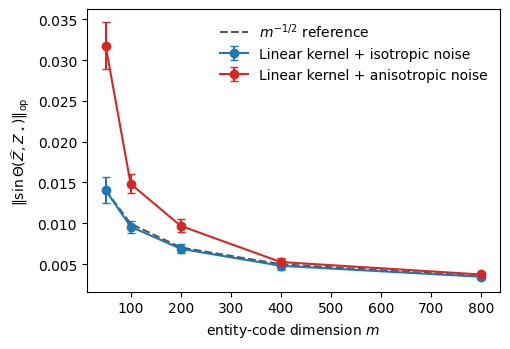

In [7]:
fig, ax = plt.subplots(figsize=(5.2, 3.6))

for regime, color, label in [
    ("isotropic", COL["isotropic"], "Linear kernel + isotropic noise"),
    ("anisotropic", COL["anisotropic"], "Linear kernel + anisotropic noise"),
]:
    g = summary_rate[summary_rate["regime"] == regime]
    ax.errorbar(g["m"], g["op_mean"], yerr=g["op_sd"], marker="o", capsize=3,
                color=color, label=label)

m0 = M_VALUES[0]
base = summary_rate[(summary_rate["regime"] == "isotropic") & (summary_rate["m"] == m0)]["op_mean"].iloc[0]
ref = base * np.sqrt(m0 / np.array(M_VALUES))
ax.plot(M_VALUES, ref, "--", color=COL["target"], label=r"$m^{-1/2}$ reference")

ax.set_xlabel("entity-code dimension $m$")
ax.set_ylabel(r"$\|\sin\Theta(\widehat Z,Z_\star)\|_{\mathrm{op}}$")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "exp1_recovery_rate_linear_only.png"), dpi=200)
plt.show()


## Experiment 2: heterogeneous views and *observable* inverse-variance weighting

We retain \((m_1,m_2,m_3,m_4)=(800,400,200,100)\) and the paper's isotropic/anisotropic regimes. Following Appendix D, use
\[
\boxed{\widehat w_s=\frac{\widehat\gamma_s/(\widehat v_s^2+10^{-9})}{\sum_{t=1}^{S}\widehat\gamma_t/(\widehat v_t^2+10^{-9})}},\qquad
\widehat v_s^2=\frac{\widehat\sigma_{\infty,s}^2\widehat B_s}{m_s}+\frac{\widehat\sigma_{\infty,s}^4}{m_s}.
\]
Every term on the right is computed **from the observed entity matrix** \(E_s\) *in the same replicate*:

- \(E_s=\widehat E_s^{(d)}+R_s\) is its rank-\(d\) SVD plus residual.
- \(\widehat\nu_s=\|R_s\|_F^2/(N-d)\) estimates \(\mathrm{tr}(\Sigma_s)/m_s\); the kernel noise shift is estimated as \(\widehat\nu_s/N\).
- \(\widehat\sigma_{\infty,s}^2= m_s\|R_s\|_{\rm op}^2/(\sqrt{m_s}+\sqrt{N-d})^2\) is an aspect-ratio-corrected, **heuristic** estimate of the noise-covariance operator norm.
- Let \(K_s^{\rm obs}=U_s\operatorname{diag}(\widehat\lambda_s)U_s^\top\). Estimate \(\widehat K_s^{\rm sig}=U_{s,d}\operatorname{diag}((\widehat\lambda_{s,1:d}-\widehat\nu_s/N)_+)U_{s,d}^\top\), \(\widehat B_s=N\max_{i,j}|\widehat K_s^{\rm sig}(i,j)|\), and \(\widehat\gamma_s=(\widehat\lambda_{s,d}-\widehat\lambda_{s,d+1})_+\).

 The **oracle** performs a ground-truth \(Z_\star\) grid search **for evaluation only** and its weights are never used in the practical rule.


In [ ]:
def make_fixed_views_for_weighting(regime, seed=2024):
    Z_star = make_z_star(N, d, seed=1)
    rng_signal = np.random.default_rng(seed)
    target_views = []
    for s in range(S):
        m = M_HET[s]
        target_views.append(
            make_view_matrices(Z_star, SPECTRA[s], m,
                               get_noise_covariance(regime, m, s, seed=seed + 700), rng_signal)
        )
    return Z_star, target_views


def sample_noisy_views_from_target(target_views, rng):
    noisy = []
    for tv in target_views:
        E = add_gaussian_noise(tv["V"], tv["Sigma"], rng)
        K_obs = linear_kernel(E)
        noisy.append({**tv, "E": E, "K_obs": K_obs})
    return noisy


def evaluate_weights_for_views(noisy_views, Z_star, weights):
    K_obs = aggregate_kernel(noisy_views, "K_obs", weights)
    Z_hat = top_eigvecs(K_obs, d)
    return sin_theta_operator(Z_hat, Z_star)


def oracle_weights_by_subspace(noisy_views, Z_star, n_grid=400, seed=123):
    """Ground-truth-aware grid benchmark, evaluation only: NOT a feasible weight rule."""
    rng = np.random.default_rng(seed)
    candidates = random_simplex_grid(n_grid, len(noisy_views), rng)
    best_w, best_err = None, np.inf
    for w in candidates:
        K_obs = aggregate_kernel(noisy_views, "K_obs", w)
        Z_hat = top_eigvecs(K_obs, d)
        err = sin_theta_operator(Z_hat, Z_star)
        if err < best_err:
            best_err, best_w = err, w
    return best_w, best_err


def run_weighting_experiment(regime, n_reps=30, seed=303, oracle_grid=400):
    Z_star, target_views = make_fixed_views_for_weighting(regime, seed=seed)
    w_uniform = np.ones(S) / S
    rows, weight_rows, diagnostics = [], [], []
    for rep in range(n_reps):
        rng = np.random.default_rng(seed + 1000 + rep)
        noisy_views = sample_noisy_views_from_target(target_views, rng)

        # CRITICAL: pass ONLY observed matrices to the practical estimator.
        observed_only = [view["E"] for view in noisy_views]
        w_iv, stats = inverse_variance_weights_from_observations(observed_only, d_rank=d)
        assert np.isclose(w_iv.sum(), 1.0) and (w_iv >= 0).all()
        # The only ground-truth-aware rule is the separately reported oracle benchmark.
        w_oracle, _ = oracle_weights_by_subspace(
            noisy_views, Z_star, n_grid=oracle_grid, seed=seed + rep
        )
        methods = {"uniform": w_uniform, "inverse_variance": w_iv, "oracle": w_oracle}
        for name, w in methods.items():
            rows.append({"regime": regime, "rep": rep, "method": name,
                         "op_error": evaluate_weights_for_views(noisy_views, Z_star, w)})
            for s in range(S):
                weight_rows.append({"regime": regime, "rep": rep, "method": name,
                                    "view": s+1, "weight": float(w[s])})
        for s, st in enumerate(stats):
            diagnostics.append({"regime": regime, "rep": rep, "view": s+1,
                                **st, "weight": float(w_iv[s])})
    return pd.DataFrame(rows), pd.DataFrame(weight_rows), pd.DataFrame(diagnostics)


df_w_iso, df_weights_iso, diag_iso = run_weighting_experiment("isotropic", n_reps=N_REPS_WEIGHT)
df_w_aniso, df_weights_aniso, diag_aniso = run_weighting_experiment("anisotropic", n_reps=N_REPS_WEIGHT)

summary_weights = (
    pd.concat([df_w_iso, df_w_aniso], ignore_index=True)
    .groupby(["regime", "method"])
    .agg(op_mean=("op_error", "mean"), op_sd=("op_error", "std"))
    .reset_index()
)
summary_weights


In [ ]:
columns = ["view", "m", "gamma_hat", "B_hat", "sigma_op_hat", "nu_hat", "v2_proxy", "weight"]
print("Isotropic observed-only plug-in diagnostics (mean across replicates):")
display(diag_iso.groupby("view", as_index=False)[columns[1:]].mean())
print("Anisotropic observed-only plug-in diagnostics (mean across replicates):")
display(diag_aniso.groupby("view", as_index=False)[columns[1:]].mean())


Isotropic observed-only plug-in diagnostics (mean across replicates):


,view,m,gamma_hat,B_hat,sigma_op_hat,nu_hat,v2_proxy,weight
0,1,800.0,2.000331,105.859003,0.061077,0.062274,0.008087,0.515114
1,2,400.0,1.498186,74.443549,0.060073,0.062112,0.011189,0.278961
2,3,200.0,0.998928,51.120683,0.060755,0.061488,0.015548,0.133916
3,4,100.0,1.799488,90.219452,0.057758,0.060024,0.052141,0.072010


Anisotropic observed-only plug-in diagnostics (mean across replicates):


,view,m,gamma_hat,B_hat,sigma_op_hat,nu_hat,v2_proxy,weight
0,1,800.0,1.998761,105.872178,0.080030,0.028387,0.010600,0.779838
1,2,400.0,1.494958,74.445450,0.187804,0.057624,0.035041,0.178109
2,3,200.0,0.984115,51.055708,0.472766,0.138771,0.121798,0.033782
3,4,100.0,1.759408,90.432919,0.973657,0.300703,0.889894,0.008272


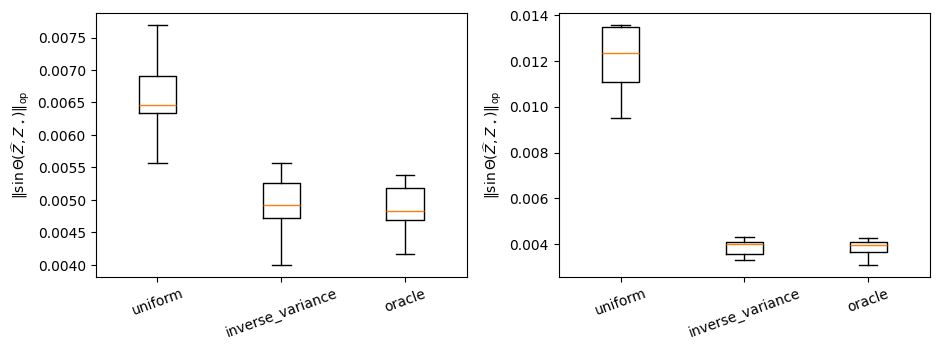

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=False)

for ax, regime, df in [
    (axes[0], "isotropic", df_w_iso),
    (axes[1], "anisotropic", df_w_aniso),
]:
    order = ["uniform", "inverse_variance", "oracle"]
    data = [df[df["method"] == m]["op_error"].values for m in order]
    ax.boxplot(data, labels=order, showfliers=False)
    ax.set_ylabel(r"$\|\sin\Theta(\widehat Z,Z_\star)\|_{\mathrm{op}}$")
    ax.tick_params(axis="x", rotation=20)

fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "exp2_weighting_boxplots_linear_only.png"), dpi=200)
plt.show()


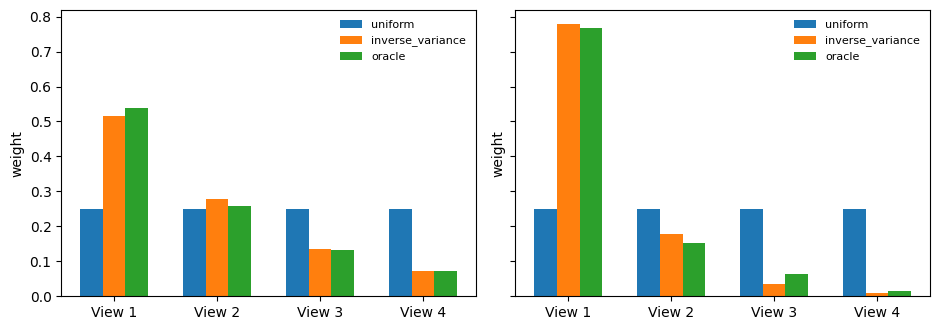

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)

for ax, regime, dfw in [
    (axes[0], "isotropic", df_weights_iso),
    (axes[1], "anisotropic", df_weights_aniso),
]:
    means = dfw.groupby(["method", "view"])["weight"].mean().reset_index()
    methods = ["uniform", "inverse_variance", "oracle"]
    width = 0.22
    x = np.arange(S)
    for i, method in enumerate(methods):
        vals = means[means["method"] == method].sort_values("view")["weight"].values
        ax.bar(x + (i - 1) * width, vals, width=width, label=method)
    ax.set_xticks(x)
    ax.set_xticklabels([f"View {i+1}" for i in range(S)])
    ax.set_ylabel("weight")
    ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "exp2_view_weights_linear_only.png"), dpi=200)
plt.show()


## Experiment 3: end-to-end supervised-risk sweeps (n, m, W)

Experiments 1–2 are unchanged. Experiment 3 keeps the paper's $N=60$, $d=4$, $S=4$, signal spectra and uniform view weights, with three changes that make each term of Theorem 2 observable:

1. **O(1)-scale coordinates.** Rows of an orthonormal $N\times d$ matrix have norm $\sqrt{d/N}$, which keeps the tanh teacher in its linear regime (a head of width 4 already suffices, so the W-sweep has no left branch). Both oracle and pretrained heads therefore take $\sqrt N\,Z$ as input; the teacher (same tanh + relation-specific bilinear form) is evaluated on $\sqrt N\,Z_\star$ and standardized to unit variance.
2. **Pretraining noise $\sigma_{\rm pre}=2.5$ (Exp. 3 only)** and a wider grid $m\in\{5,\dots,800\}$, so that $\|\sin\Theta(\widehat Z,Z_\star)\|_F$ ranges from about 0.57 to 0.05. At $\sigma=0.25$ the representation error is invisible in the downstream MSE.
3. **W stays below the interpolation threshold.** As in the paper, $W$ is the number of trainable parameters of each relation head $F_r$: a head of hidden width $w$ has $W=w(2d+2)+1=10w+1$ parameters. With $n=900$ (about 300 triples per relation), the interpolation threshold is $W\approx 300$, so the grid $w\in\{1,\dots,24\}$ stops at $W=241$. Crossing the threshold produces double descent, not the bias–variance U-shape of Theorem 2. (With $d=16$, each hidden unit costs 34 parameters and the threshold falls at width $w\approx 8$–$16$, which is where the earlier peak appeared.)

The heads are trained to near-ERM (full-batch Adam, cosine decay, 3000 steps, no early stopping). Test MSE is computed against the noiseless teacher $\gamma$ on all held-out triples, i.e. the triples among the $N^2K$ that were not drawn into the labeled sample. Oracle and pretrained runs share each seed's labeled sample, and every seed draws fresh pretraining data.


In [12]:
import torch
import torch.nn as nn
from joblib import Parallel, delayed

# ---------------- Experiment 3 settings ----------------
K_REL = 3
SIGMA_PRE = 2.5          # pretraining noise scale (Exp. 3 only)
SIGMA_LABEL = 0.3        # label noise; teacher standardized to unit variance
EPOCHS, LR = 3000, 1e-2
HEAD_CLIP = 5.0
N_SEEDS = 20
N_JOBS = 20

N_VALS = [200, 400, 800, 1600, 3200, 6400]
M_VALS = [5, 10, 20, 40, 80, 160, 400, 800]
WIDTH_VALS = [1, 2, 4, 8, 12, 16, 20, 24]   # hidden width per relation head


def n_params(width):
    """W = number of parameters of one relation head f_r: width*(2d+2)+1."""
    return width * (2 * d + 2) + 1


W_VALS = [n_params(w) for w in WIDTH_VALS]   # 11..241, below the threshold n/K ~ 300

N_SWEEP_FIX = dict(m=40, width=8)
M_SWEEP_FIX = dict(n=3000, width=16)
W_SWEEP_FIX = dict(n=900, m=40)

Z_STAR = make_z_star(N, d, seed=1)


def kpca_embed(m, seed):
    """Algorithm 1 (linear kernel, uniform weights) with isotropic noise sigma_pre."""
    rng = np.random.default_rng(10_000 + 97 * m + seed)
    K_obs = np.zeros((N, N))
    for s in range(S):
        V, _ = make_signal_codes(Z_STAR, SPECTRA[s], m, rng)
        E = V + SIGMA_PRE * rng.standard_normal((N, m)) / np.sqrt(m)
        K_obs += UNIFORM_W[s] * linear_kernel(E)
    Z_hat = top_eigvecs(K_obs, d)
    return Z_hat, sin_theta_fro(Z_hat, Z_STAR)


def make_teacher(seed=5, hidden=32):
    """gamma(h,r,t) = u^T tanh(A [z_h; z_t; e_r] + b) + <beta_r, z_h * z_t> + c_r on sqrt(N) Z_star."""
    rng = np.random.default_rng(seed)
    A = rng.standard_normal((hidden, 2 * d + K_REL))
    b = 0.5 * rng.standard_normal(hidden)
    u = rng.standard_normal(hidden) / np.sqrt(hidden)
    beta = 0.5 * rng.standard_normal((K_REL, d))
    c = 0.1 * rng.standard_normal(K_REL)
    X = np.sqrt(N) * Z_STAR
    Xh, Xt = np.repeat(X, N, 0), np.tile(X, (N, 1))
    out = np.zeros((K_REL, N, N))
    for r in range(K_REL):
        e = np.zeros((N * N, K_REL)); e[:, r] = 1.0
        out[r] = (np.tanh(np.c_[Xh, Xt, e] @ A.T + b) @ u + (Xh * Xt) @ beta[r] + c[r]).reshape(N, N)
    return (out - out.mean()) / out.std()


GAMMA = make_teacher()
ALL_TRIPLES = np.array([(r, h, t) for r in range(K_REL) for h in range(N) for t in range(N)])


class RelationWiseReLU(nn.Module):
    """One bounded one-hidden-layer ReLU head f_r per relation (eq. 3.7)."""
    def __init__(self, width):
        super().__init__()
        self.W1 = nn.Parameter(torch.randn(K_REL, width, 2 * d) * np.sqrt(1.0 / d))
        self.b1 = nn.Parameter(torch.zeros(K_REL, width))
        self.W2 = nn.Parameter(torch.randn(K_REL, width) / np.sqrt(width))
        self.b2 = nn.Parameter(torch.zeros(K_REL))

    def forward(self, x, r):
        h = torch.relu(torch.einsum('nwi,ni->nw', self.W1[r], x) + self.b1[r])
        return torch.clamp((h * self.W2[r]).sum(1) + self.b2[r], -HEAD_CLIP, HEAD_CLIP)


def train_heads(Z, n, width, seed):
    """Fit relation heads on n noisy triples; return MSE vs. gamma on all held-out (unsampled) triples."""
    torch.set_num_threads(1)
    rng = np.random.default_rng(seed); torch.manual_seed(seed)
    X = np.sqrt(N) * Z
    idx = rng.integers(0, len(ALL_TRIPLES), n)
    r, h, t = ALL_TRIPLES[idx].T
    y = GAMMA[r, h, t] + SIGMA_LABEL * rng.standard_normal(n)
    x_tr = torch.tensor(np.c_[X[h], X[t]], dtype=torch.float32)
    r_tr, y_tr = torch.tensor(r), torch.tensor(y, dtype=torch.float32)
    model = RelationWiseReLU(width)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
    for _ in range(EPOCHS):
        opt.zero_grad(set_to_none=True)
        ((model(x_tr, r_tr) - y_tr) ** 2).mean().backward()
        opt.step(); sched.step()
    ra, ha, ta = ALL_TRIPLES[np.setdiff1d(np.arange(len(ALL_TRIPLES)), idx)].T
    with torch.no_grad():
        pred = model(torch.tensor(np.c_[X[ha], X[ta]], dtype=torch.float32), torch.tensor(ra)).numpy()
    return float(np.mean((pred - GAMMA[ra, ha, ta]) ** 2))


def run_job(n, m, width, seed):
    Z_hat, err = kpca_embed(m, seed)
    return dict(n=n, m=m, width=width, W=n_params(width), seed=seed, sin_theta_F=err,
                oracle=train_heads(Z_STAR, n, width, seed),
                pretrained=train_heads(Z_hat, n, width, seed))


def run_sweep(configs):
    jobs = [delayed(run_job)(n, m, width, s) for (n, m, width) in configs for s in range(N_SEEDS)]
    return pd.DataFrame(Parallel(n_jobs=N_JOBS)(jobs))


def summarize(df, key):
    return df.groupby(key).agg(oracle_mean=("oracle", "mean"), oracle_sd=("oracle", "std"),
                               pre_mean=("pretrained", "mean"), pre_sd=("pretrained", "std"),
                               sin_theta_F=("sin_theta_F", "mean")).reset_index()


df_n = run_sweep([(n, N_SWEEP_FIX["m"], N_SWEEP_FIX["width"]) for n in N_VALS])
df_m = run_sweep([(M_SWEEP_FIX["n"], m, M_SWEEP_FIX["width"]) for m in M_VALS])
df_w = run_sweep([(W_SWEEP_FIX["n"], W_SWEEP_FIX["m"], w) for w in WIDTH_VALS])
summary_n, summary_m, summary_w = summarize(df_n, "n"), summarize(df_m, "m"), summarize(df_w, "W")

print(f"n-sweep (m={N_SWEEP_FIX['m']}, W={n_params(N_SWEEP_FIX['width'])})"); display(summary_n)
print(f"m-sweep (n={M_SWEEP_FIX['n']}, W={n_params(M_SWEEP_FIX['width'])})"); display(summary_m)
print(f"W-sweep (n={W_SWEEP_FIX['n']}, m={W_SWEEP_FIX['m']})"); display(summary_w)


n-sweep (m=40, W=81)


,n,oracle_mean,oracle_sd,pre_mean,pre_sd,sin_theta_F
0,200,1.249783,0.292658,1.302841,0.201977,0.217309
1,400,0.503713,0.085622,0.532646,0.069237,0.217309
2,800,0.271440,0.037096,0.296527,0.033388,0.217309
3,1600,0.194276,0.022562,0.217388,0.024723,0.217309
4,3200,0.152977,0.014829,0.181990,0.017415,0.217309
5,6400,0.141279,0.019182,0.163443,0.015059,0.217309


m-sweep (n=3000, W=161)


,m,oracle_mean,oracle_sd,pre_mean,pre_sd,sin_theta_F
0,5,0.114708,0.004165,0.280752,0.027119,0.574380
1,10,0.114708,0.004165,0.207559,0.013950,0.422227
2,20,0.114708,0.004165,0.167864,0.008182,0.308014
3,40,0.114708,0.004165,0.143138,0.005093,0.217309
4,80,0.114708,0.004165,0.128160,0.005263,0.154270
5,160,0.114708,0.004165,0.123736,0.006251,0.109783
6,400,0.114708,0.004165,0.118708,0.005000,0.070786
7,800,0.114708,0.004165,0.117900,0.006010,0.048556


W-sweep (n=900, m=40)


,W,oracle_mean,oracle_sd,pre_mean,pre_sd,sin_theta_F
0,11,0.807021,0.037584,0.806149,0.039458,0.217309
1,21,0.652480,0.038133,0.660448,0.030837,0.217309
2,41,0.440856,0.030577,0.465969,0.042329,0.217309
3,81,0.256332,0.032577,0.281363,0.030694,0.217309
4,121,0.221418,0.019543,0.258285,0.021547,0.217309
5,161,0.239183,0.024235,0.280291,0.022246,0.217309
6,201,0.267506,0.022074,0.311108,0.024325,0.217309
7,241,0.298400,0.023095,0.360833,0.029425,0.217309


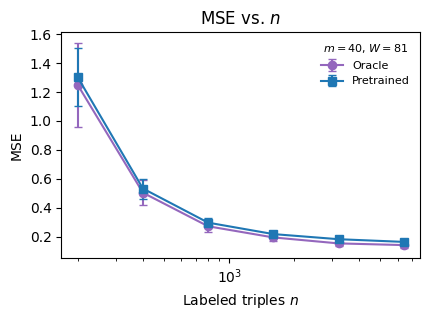

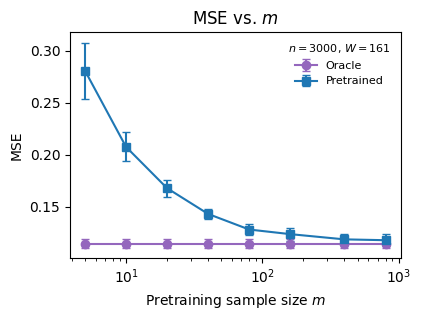

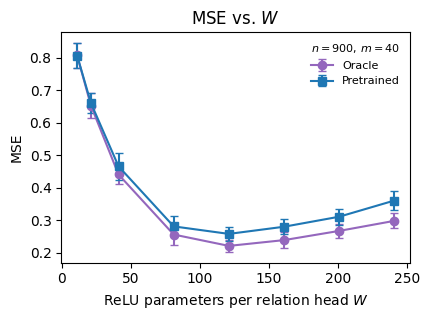

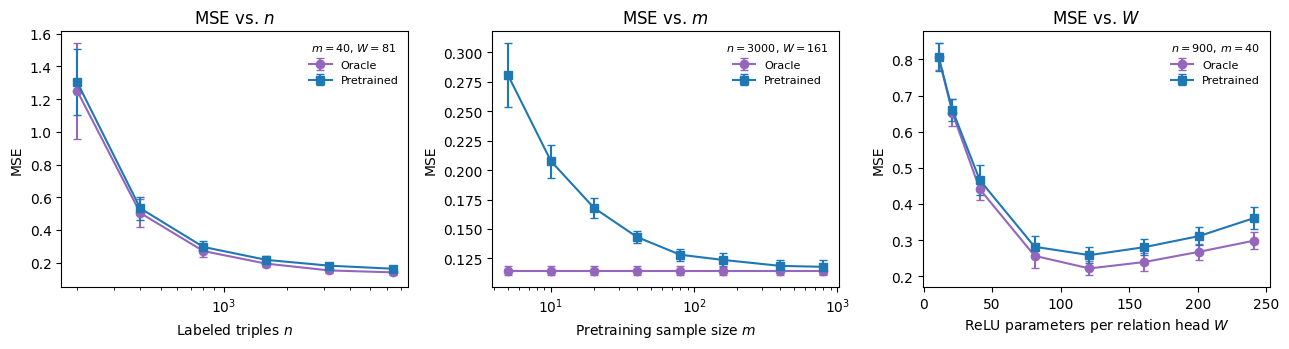

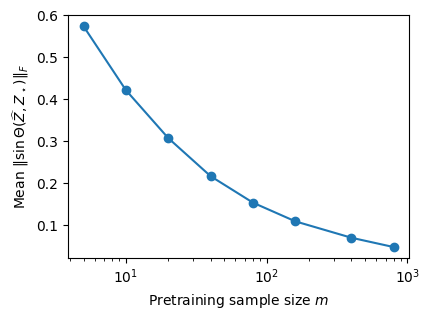

In [13]:
FIGDIR = "figures"
os.makedirs(FIGDIR, exist_ok=True)


def sweep_plot(ax, summ, key, xlabel, logx, title, fixed):
    ax.errorbar(summ[key], summ["oracle_mean"], yerr=summ["oracle_sd"], fmt="o-",
                color=COL["oracle"], capsize=3, label="Oracle")
    ax.errorbar(summ[key], summ["pre_mean"], yerr=summ["pre_sd"], fmt="s-",
                color=COL["pretrained"], capsize=3, label="Pretrained")
    if logx:
        ax.set_xscale("log")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("MSE")
    ax.legend(fontsize=8, frameon=False)  # fixed settings are reported in the appendix


panels = [
    (summary_n, "n", "Labeled triples $n$", True, "MSE vs. $n$",
     f"$m={N_SWEEP_FIX['m']}$, $W={n_params(N_SWEEP_FIX['width'])}$", "exp3_n_sweep_linear_only.png"),
    (summary_m, "m", "Pretraining sample size $m$", True, "MSE vs. $m$",
     f"$n={M_SWEEP_FIX['n']}$, $W={n_params(M_SWEEP_FIX['width'])}$", "exp3_m_sweep_linear_only.png"),
    (summary_w, "W", "ReLU parameters per relation head $W$", False, "MSE vs. $W$",
     f"$n={W_SWEEP_FIX['n']}$, $m={W_SWEEP_FIX['m']}$", "exp3_w_sweep_linear_only.png"),
]
for *args, fname in panels:
    fig, ax = plt.subplots(figsize=(4.4, 3.3))
    sweep_plot(ax, *args)
    fig.tight_layout(); fig.savefig(os.path.join(FIGDIR, fname), dpi=200); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (*args, _) in zip(axes, panels):
    sweep_plot(ax, *args)
fig.tight_layout(); fig.savefig(os.path.join(FIGDIR, "exp3_supervised_sweeps_linear_only.png"), dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(4.4, 3.3))
ax.plot(summary_m["m"], summary_m["sin_theta_F"], "o-", color=COL["pretrained"])
ax.set_xscale("log"); ax.set_xlabel("Pretraining sample size $m$")
ax.set_ylabel(r"Mean $\|\sin\Theta(\widehat Z,Z_\star)\|_F$")
fig.tight_layout(); fig.savefig(os.path.join(FIGDIR, "exp3_m_subspace_diagnostic.png"), dpi=200); plt.show()
